# Lazy DAG with bind() and InputNode

The same graph style in bind mode: .bind() builds a lazy Ray DAG around an InputNode, and execute(x=5) runs it with a concrete input.

**When to use it.** When you want to build a DAG once and execute it many times with different inputs.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

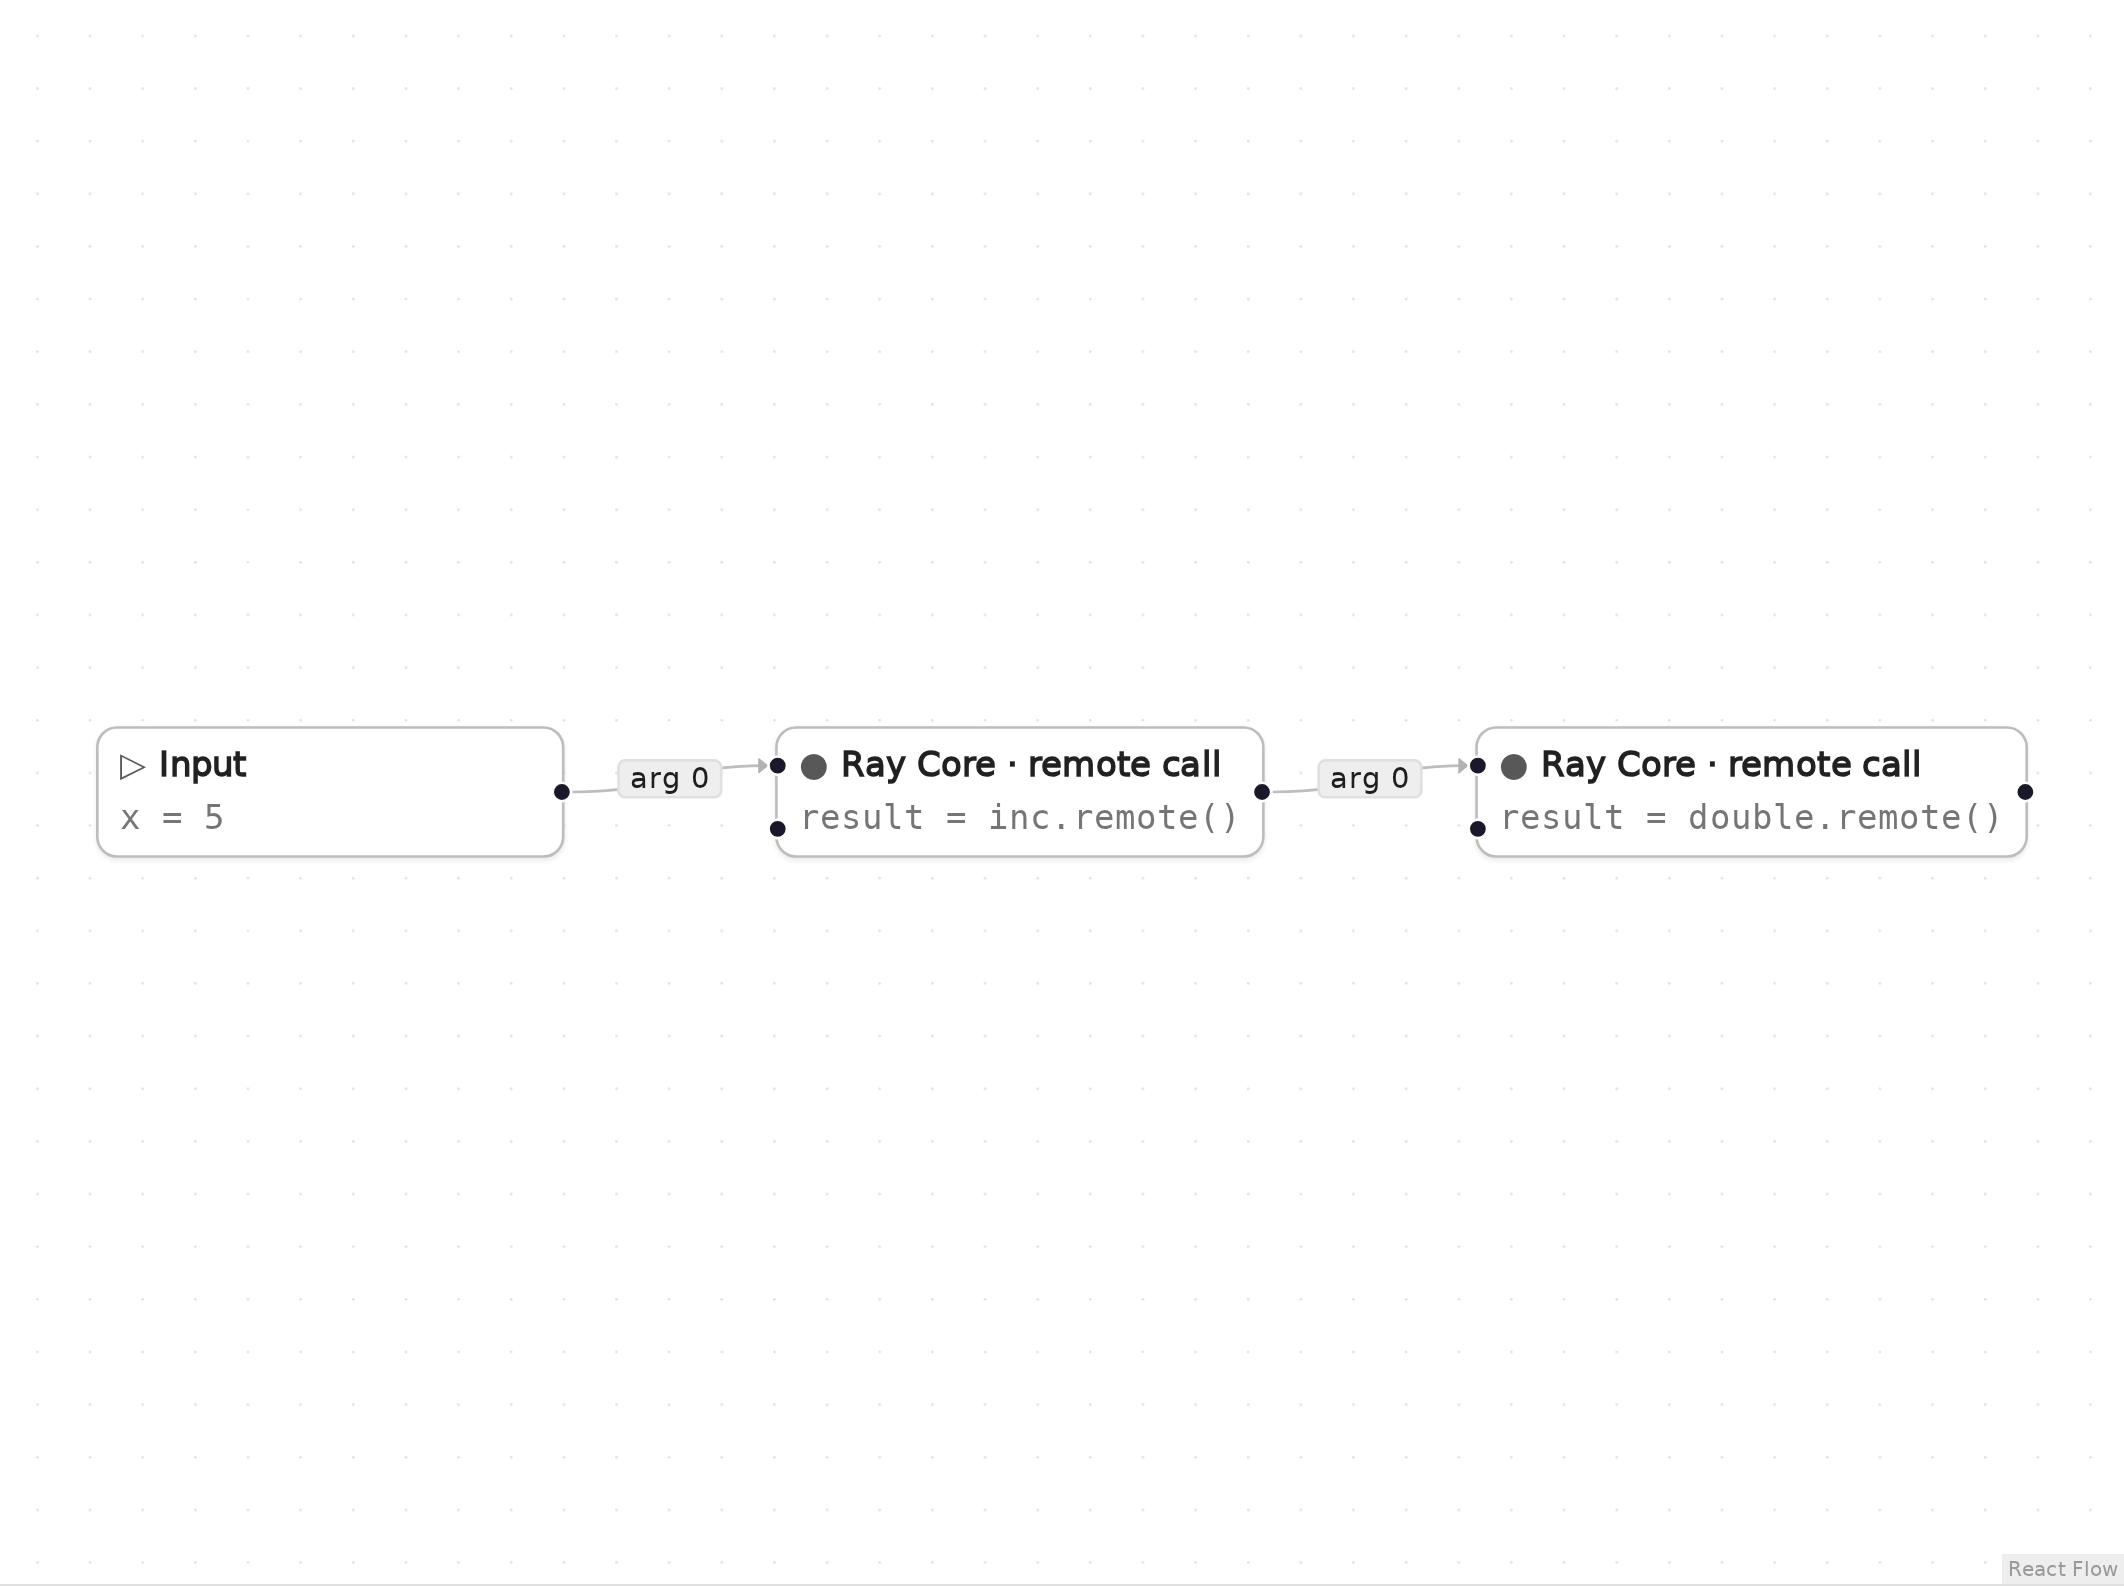

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
def inc(x):
    return x + 1


def double(x):
    return x * 2

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray
from ray.dag import InputNode

if not ray.is_initialized():
    ray.init()

# Inputs
x: int = 5

with InputNode() as dag_input:
    _n1 = ray.remote(inc).bind(dag_input["x"])
    _n2 = ray.remote(double).bind(_n1)
result = ray.get(_n2.execute(x=5))

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
assert result == 12, result
print("result =", result)

result = 12


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–4 and 6–7)

```python
# Generated with Eugo's visual Ray builder
...
import ray
from ray.dag import InputNode
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Input** (node `i1`, lines 10 and 12)

```python
x: int = 5
...
with InputNode() as dag_input:
```

Inside the with InputNode() block, dag_input["x"] is a placeholder that execute(x=...) fills in.

**Remote task** (node `n1`, line 13)

```python
    _n1 = ray.remote(inc).bind(dag_input["x"])
```

.bind() records the call instead of running it.

**Remote task** (node `n2`, lines 14–15)

```python
    _n2 = ray.remote(double).bind(_n1)
result = ray.get(_n2.execute(x=5))
```

double receives the result of node `n1` and multiplies it by two, so the DAG computes (x + 1) * 2. execute() runs the whole recorded DAG; ray.get returns the final value.

execute(x=5) passes the Input node's default as a literal. To run with another value, change the argument to execute(); the `x` variable on line 10 is not read.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()